# YZM 411 Bilgisayarlı Görü — Ödev 1: Renk, Aydınlatma ve Örnekleme

**Giriş dosyaları:** `foto/normal.jpg`, `foto/golge.jpg`, `foto/lamba.jpg` (kendi çekiminiz, aynı kamera konumu),
`ayarlar.json` (koordinatlar ve parametreler), `metin.json` (tahminleriniz ve yorumlarınız).

**Çalıştırma sırası**
1. Üç fotoğrafı `foto/` klasörüne koyun.
2. `metin.json` içindeki **tahmin** alanlarını deneyi çalıştırmadan *önce* kendi cümlelerinizle yazın.
3. Notebook'u bir kez çalıştırın → `cikti/koordinat_izgarasi.png` dosyasından nesne, 3 piksel ve yazı bölgesinin koordinatlarını okuyup `ayarlar.json`'a yazın.
4. *Kernel → Restart & Run All*. Tüm ölçümler `cikti/` klasörüne yazılır.
5. Sonuçlara bakıp `metin.json` içindeki *ne_gordum / neden / kontrol* alanlarını ve iki soruyu doldurun, son iki hücreyi tekrar çalıştırın (rapor + ZIP).

Koordinat kuralı: NumPy erişimi `img[y, x, kanal]`; ayarlarda pikseller `[x, y]`, kutular `[x, y, genişlik, yükseklik]` olarak yazılır.

In [1]:
# 0) Paketler ve sürümler
import sys, json, platform, zipfile, textwrap, datetime
from pathlib import Path
import numpy as np
import cv2
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
try:
    import PIL
    from PIL import Image
    PIL_SURUM = PIL.__version__
except ImportError:
    Image, PIL_SURUM = None, "yok"

KOK = Path.cwd()
CIKTI = KOK / "cikti"
CIKTI.mkdir(exist_ok=True)

SURUMLER = {
    "python": platform.python_version(),
    "numpy": np.__version__,
    "opencv": cv2.__version__,
    "pandas": pd.__version__,
    "matplotlib": matplotlib.__version__,
    "pillow": PIL_SURUM,
    "platform": platform.platform(),
    "calistirma_zamani": datetime.datetime.now().isoformat(timespec="seconds"),
}
for k, v in SURUMLER.items():
    print(f"{k:18s}: {v}")

python            : 3.12.10
numpy             : 2.2.6
opencv            : 4.12.0
pandas            : 2.3.3
matplotlib        : 3.10.8
pillow            : 11.3.0
platform          : Windows-11-10.0.26200-SP0
calistirma_zamani : 2026-11-11T12:37:57


In [2]:
# 1) Ayarlar ve metin dosyası
AYAR = json.loads((KOK / "ayarlar.json").read_text(encoding="utf-8"))
METIN = json.loads((KOK / "metin.json").read_text(encoding="utf-8"))
print(json.dumps({k: v for k, v in AYAR.items() if not k.startswith("_")}, indent=1, ensure_ascii=False))

def eksik_mi(s):
    return (not s) or (not str(s).strip()) or str(s).strip().upper().startswith("TASLAK")

def tahmin_kontrol(adim):
    t = METIN["deneyler"][adim]["tahmin"]
    if eksik_mi(t):
        print(f"!!! UYARI: Adım {adim} için tahmin yazılmamış veya hâlâ TASLAK. Tahmini olmayan deney puanlanmaz.")
    print(f"Adım {adim} tahmini (çalıştırmadan önce yazılan): {t}\n")

SONUC = []          # (adım, ölçüm, değer) satırları -> cikti/sonuc_tablosu.csv
def kaydet(adim, olcum, deger):
    SONUC.append({"adim": adim, "olcum": olcum, "deger": deger})

{
 "ogrenci_no": "230212010",
 "fotograflar": {
  "normal": "foto/normal.jpg",
  "golge": "foto/golge_SIMULE.jpg",
  "lamba": "foto/lamba_SIMULE.jpg"
 },
 "nesne_ornek_kutu": [
  120,
  1040,
  120,
  120
 ],
 "nesne_tam_kutu": null,
 "pikseller": [
  [
   200,
   1100
  ],
  [
   1100,
   950
  ],
  [
   1450,
   300
  ]
 ],
 "yazi_kutu": [
  1000,
  560,
  240,
  140
 ],
 "esik_payi": {
  "rgb": 25,
  "h": 6,
  "s_alt": 40,
  "v_alt": 40
 },
 "esik_manuel": null,
 "parlaklik_b": 40,
 "gamalar": [
  0.5,
  2.0
 ],
 "kucultme_orani": 4,
 "simule_kosullar": [
  "golge",
  "lamba"
 ]
}


In [3]:
# 2) Fotoğrafları oku (OpenCV -> BGR). Türkçe karakterli yollar için imdecode kullanılır.
KOSULLAR = ["normal", "golge", "lamba"]
ADLAR = {"normal": "Normal ışık", "golge": "Gölge", "lamba": "Farklı lamba"}
SIMULE = AYAR.get("simule_kosullar", [])
for _k in SIMULE:
    ADLAR[_k] += " (simüle)"
if SIMULE:
    print("!!! DİKKAT: Şu koşullar gerçek çekim değil, simule_et.py ile üretildi:", SIMULE)

def oku_bgr(yol):
    yol = Path(yol)
    if not yol.exists():
        raise FileNotFoundError(f"Bulunamadı: {yol}  -> fotoğrafı foto/ klasörüne koyun veya ayarlar.json'u düzeltin")
    veri = np.fromfile(str(yol), dtype=np.uint8)
    im = cv2.imdecode(veri, cv2.IMREAD_COLOR)
    if im is None:
        raise ValueError(f"Görüntü çözülemedi: {yol}")
    return im

bgr = {k: oku_bgr(KOK / AYAR["fotograflar"][k]) for k in KOSULLAR}
sekiller = {k: v.shape for k, v in bgr.items()}
print("Boyutlar:", sekiller)
if len(set(sekiller.values())) != 1:
    raise ValueError("Üç fotoğraf aynı boyutta olmalı (aynı kamera, aynı ayar, kırpma yok).")

rgb = {k: cv2.cvtColor(v, cv2.COLOR_BGR2RGB) for k, v in bgr.items()}
H, W, C = rgb["normal"].shape

!!! DİKKAT: Şu koşullar gerçek çekim değil, simule_et.py ile üretildi: ['golge', 'lamba']
Boyutlar: {'normal': (1411, 1600, 3), 'golge': (1411, 1600, 3), 'lamba': (1411, 1600, 3)}


In [4]:
# 3) EXIF: otomatik pozlama / beyaz dengesi açık mı? (Ödev adım 2c)
EXIF_ETIKET = {0x010F: "Marka", 0x0110: "Model", 0x829A: "PozlamaSuresi", 0x829D: "FNumarasi",
               0x8827: "ISO", 0xA402: "PozlamaModu", 0xA403: "BeyazDengesi", 0x8822: "PozlamaProgrami"}
MOD = {"PozlamaModu": {0: "otomatik", 1: "manuel", 2: "otomatik braket"},
       "BeyazDengesi": {0: "otomatik", 1: "manuel"}}

def exif_oku(yol):
    satir = {}
    if Image is None:
        return satir
    try:
        with Image.open(yol) as im:
            ex = im.getexif()
            alt = ex.get_ifd(0x8769) if hasattr(ex, "get_ifd") else {}
            tum = {**dict(ex), **dict(alt)}
            for kod, ad in EXIF_ETIKET.items():
                if kod in tum:
                    v = tum[kod]
                    v = float(v) if hasattr(v, "numerator") else v
                    satir[ad] = MOD.get(ad, {}).get(v, v)
    except Exception as e:
        satir["hata"] = str(e)
    return satir

exif = pd.DataFrame({ADLAR[k]: exif_oku(KOK / AYAR["fotograflar"][k]) for k in KOSULLAR}).T
exif.to_csv(CIKTI / "exif.csv", encoding="utf-8-sig")
display(exif) if len(exif.columns) else print("EXIF bilgisi yok (ekran görüntüsü / düzenlenmiş dosya olabilir). Kamera ayarını metin.json'da elle not edin.")
OTOMATIK_UYARI = any(c in exif.columns and exif[c].astype(str).str.contains("otomatik").any()
                     for c in ["PozlamaModu", "BeyazDengesi"])
if OTOMATIK_UYARI:
    print("NOT: Otomatik pozlama/beyaz dengesi açık -> 'yalnızca ışık değişti' diye kesin iddia edilemez.")

EXIF bilgisi yok (ekran görüntüsü / düzenlenmiş dosya olabilir). Kamera ayarını metin.json'da elle not edin.


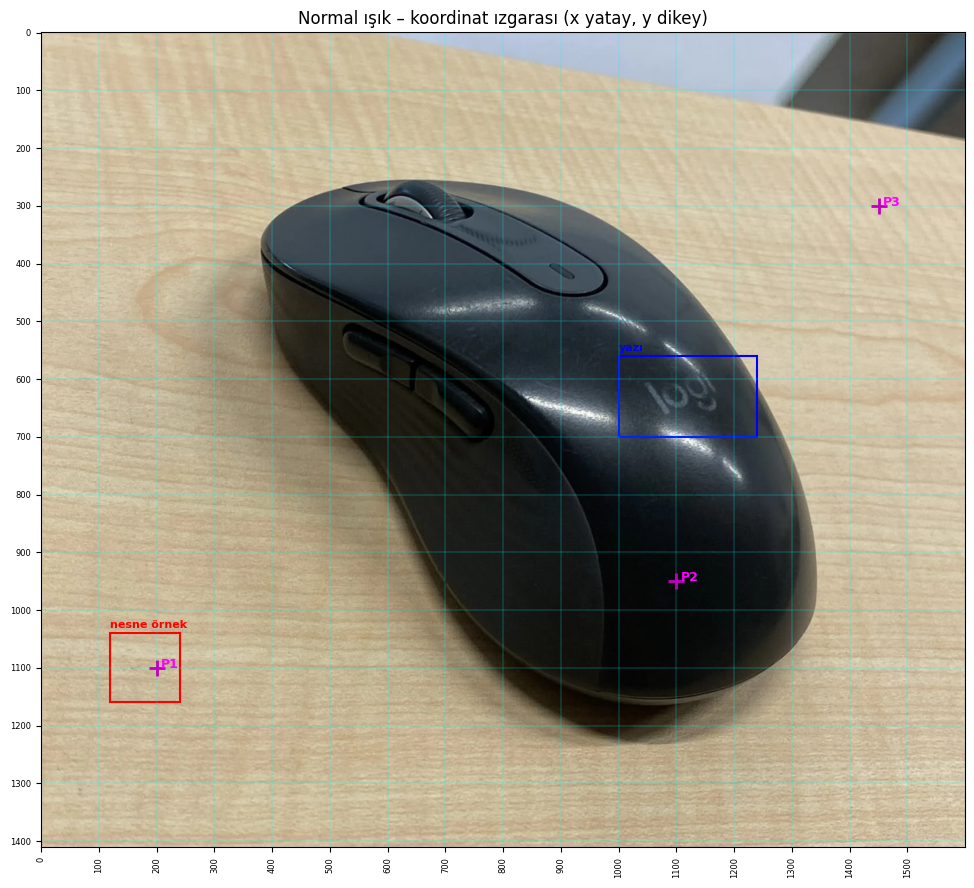

In [5]:
# 4) Koordinat yardımcı ızgarası: nesne/piksel/yazı koordinatlarını buradan okuyup ayarlar.json'a yazın
def kutu_kes(img, kutu):
    x, y, w, h = [int(v) for v in kutu]
    return img[y:y + h, x:x + w]

def kutu_ciz(ax, kutu, renk, etiket):
    x, y, w, h = kutu
    ax.add_patch(plt.Rectangle((x, y), w, h, fill=False, ec=renk, lw=1.5))
    ax.text(x, y - 5, etiket, color=renk, fontsize=8, va="bottom", weight="bold")

adim = max(50, int(round(max(H, W) / 20 / 50.0)) * 50)
fig, ax = plt.subplots(figsize=(12, 12 * H / W))
ax.imshow(rgb["normal"])
ax.set_xticks(np.arange(0, W, adim)); ax.set_yticks(np.arange(0, H, adim))
ax.tick_params(labelsize=6); plt.setp(ax.get_xticklabels(), rotation=90)
ax.grid(True, color="cyan", lw=0.3, alpha=0.7)
kutu_ciz(ax, AYAR["nesne_ornek_kutu"], "red", "nesne örnek")
if AYAR.get("nesne_tam_kutu"):
    kutu_ciz(ax, AYAR["nesne_tam_kutu"], "orange", "nesne tam")
kutu_ciz(ax, AYAR["yazi_kutu"], "blue", "yazı")
for i, (px, py) in enumerate(AYAR["pikseller"]):
    ax.plot(px, py, "m+", ms=12, mew=2); ax.text(px + 8, py, f"P{i+1}", color="magenta", fontsize=9, weight="bold")
ax.set_title("Normal ışık – koordinat ızgarası (x yatay, y dikey)")
fig.savefig(CIKTI / "koordinat_izgarasi.png", dpi=150, bbox_inches="tight"); plt.show()

for ad, kutu in [("nesne_ornek_kutu", AYAR["nesne_ornek_kutu"]), ("yazi_kutu", AYAR["yazi_kutu"])]:
    x, y, w, h = kutu
    assert 0 <= x and 0 <= y and x + w <= W and y + h <= H and w > 0 and h > 0, f"{ad} görüntü dışına taşıyor: {kutu}, görüntü {W}x{H}"
for px, py in AYAR["pikseller"]:
    assert 0 <= px < W and 0 <= py < H, f"piksel ({px},{py}) görüntü dışında"

## Adım 4 — Görüntünün sayısal yapısı (Hedef 1)

In [6]:
tahmin_kontrol("4")
I = bgr["normal"]
print(f"img.shape = {I.shape}  (H x W x C)   dtype = {I.dtype}   min = {I.min()}  max = {I.max()}")
kaydet(4, "boyut (H,W,C)", str(I.shape)); kaydet(4, "veri türü", str(I.dtype)); kaydet(4, "değer aralığı", f"{I.min()}-{I.max()}")

# img[y, x, kanal] erişimi ve BGR -> RGB
px, py = AYAR["pikseller"][0]
print(f"\nNumPy erişimi img[y={py}, x={px}]  (önce satır=y, sonra sütun=x)")
print("  OpenCV BGR :", I[py, px], " -> I[y, x, 0] =", I[py, px, 0], "(bu MAVİ kanaldır)")
R = rgb["normal"]
print("  RGB        :", R[py, px], " -> R[y, x, 0] =", R[py, px, 0], "(bu KIRMIZI kanaldır)")
assert np.array_equal(R, I[..., ::-1]), "cvtColor ile kanal ters çevirme aynı olmalı"
assert R[py, px, 0] == I[py, px, 2]
print("  Kontrol: cv2.cvtColor(BGR2RGB) == img[..., ::-1]  ->  True")

# Aynı fiziksel bölgedeki 3 pikselin üç fotoğraftaki RGB değerleri (+ 5x5 komşuluk ortalaması, gürültü kontrolü için)
satirlar = []
for i, (px, py) in enumerate(AYAR["pikseller"]):
    for k in KOSULLAR:
        v = rgb[k][py, px].astype(int)
        komsu = rgb[k][max(0, py - 2):py + 3, max(0, px - 2):px + 3].reshape(-1, 3).mean(0)
        satirlar.append({"piksel": f"P{i+1}", "x": px, "y": py, "kosul": ADLAR[k],
                         "R": v[0], "G": v[1], "B": v[2],
                         "R_5x5": round(komsu[0], 1), "G_5x5": round(komsu[1], 1), "B_5x5": round(komsu[2], 1)})
piksel_df = pd.DataFrame(satirlar)
piksel_df.to_csv(CIKTI / "adim4_pikseller.csv", index=False, encoding="utf-8-sig")
display(piksel_df)

Adım 4 tahmini (çalıştırmadan önce yazılan): Masa pikseli P1 simüle gölgede üç kanalda da yaklaşık yarıya düşecek, B oransal olarak daha az düşecek; simüle lambada R artacak, B belirgin düşecek. Neredeyse siyah fare pikseli P2 (≈4, 8, 9) mutlak olarak çok az değişecek, çünkü çarpımsal ışık değişimi küçük değeri az kaydırır.

img.shape = (1411, 1600, 3)  (H x W x C)   dtype = uint8   min = 0  max = 255

NumPy erişimi img[y=1100, x=200]  (önce satır=y, sonra sütun=x)
  OpenCV BGR : [153 188 202]  -> I[y, x, 0] = 153 (bu MAVİ kanaldır)
  RGB        : [202 188 153]  -> R[y, x, 0] = 202 (bu KIRMIZI kanaldır)
  Kontrol: cv2.cvtColor(BGR2RGB) == img[..., ::-1]  ->  True


,piksel,x,y,kosul,R,G,B,R_5x5,G_5x5,B_5x5
0,P1,200,1100,Normal ışık,202,188,153,204.6,190.0,155.8
1,P1,200,1100,Gölge (simüle),117,113,101,118.1,114.5,102.2
2,P1,200,1100,Farklı lamba (simüle),177,142,88,179.1,143.3,89.7
3,P2,1100,950,Normal ışık,4,8,9,4.5,8.5,9.5
4,P2,1100,950,Gölge (simüle),2,3,5,1.9,2.9,4.9
5,P2,1100,950,Farklı lamba (simüle),2,2,2,3.3,3.3,3.3
6,P3,1450,300,Normal ışık,211,197,170,211.3,197.3,170.3
7,P3,1450,300,Gölge (simüle),141,135,123,142.3,136.3,124.3
8,P3,1450,300,Farklı lamba (simüle),165,134,88,162.7,131.0,85.3


## Adım 5 — Sabit RGB ve HSV eşikleri (Hedef 2)
Eşikler **yalnızca normal ışıklı fotoğraftaki nesne örnek kutusundan** hesaplanır, `cikti/esikler.json`'a yazılarak dondurulur ve üç fotoğrafa aynen uygulanır.

Adım 5 tahmini (çalıştırmadan önce yazılan): Hedef renkli bölge bej masa (H≈20, S≈55) olduğu için normal ışıkta maske masanın büyük kısmını seçecek. Gölgede tüm kanallar ve V alt eşiğin altına ineceği için hem RGB hem HSV maskesi neredeyse sıfırlanacak; lambada B düştüğü için RGB maskesi küçülecek, HSV'de ise ton turuncuya kaydığı ve S arttığı için maske kısmen korunacak.

DONDURULAN EŞİKLER: {"rgb_alt": [165, 147, 115], "rgb_ust": [243, 232, 202], "h_alt": 12, "h_ust": 29, "s_alt": 5, "v_alt": 150, "kaynak": "normal ışık, kutu [120, 1040, 120, 120], yüzdelik %2-%98, pay {'rgb': 25, 'h': 6, 's_alt': 40, 'v_alt': 40}"}


,kosul,ornek_bolge_ort_RGB,ornek_bolge_medyan_HSV,RGB_alan_orani_%,RGB_ornek_kutu_ici_%,HSV_alan_orani_%,HSV_ornek_kutu_ici_%
0,Normal ışık,"(204, 188, 157)","(20, 60, 204)",64.172,100.0,66.115,100.0
1,Gölge (simüle),"(118, 114, 103)","(22, 35, 118)",1.634,0.0,2.066,0.0
2,Farklı lamba (simüle),"(178, 142, 90)","(18, 127, 178)",10.315,0.0,54.990,100.0


Not: alan oranı bir DOĞRULUK ölçütü değildir; yalnızca eşiği geçen piksel payıdır.


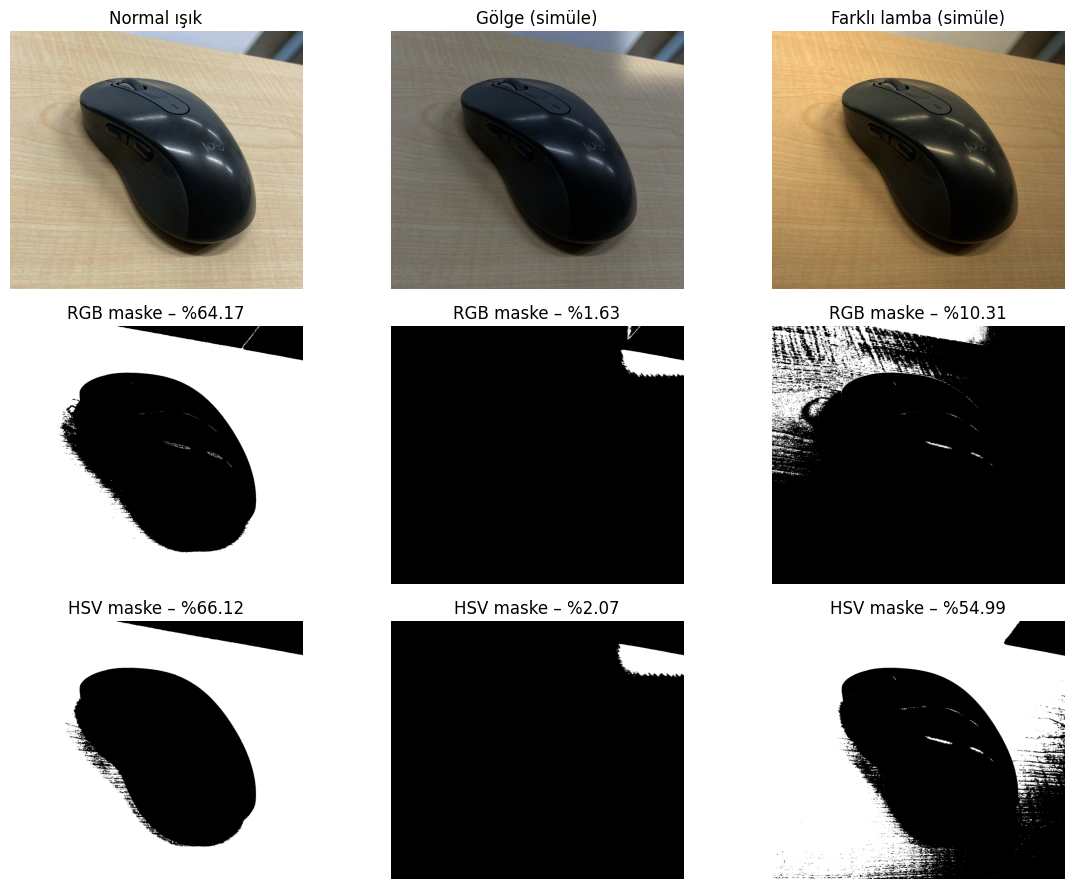

In [7]:
tahmin_kontrol("5")
PAY = AYAR["esik_payi"]

def esik_hesapla(bgr_img, kutu):
    bolge_rgb = cv2.cvtColor(kutu_kes(bgr_img, kutu), cv2.COLOR_BGR2RGB).reshape(-1, 3).astype(float)
    bolge_hsv = cv2.cvtColor(kutu_kes(bgr_img, kutu), cv2.COLOR_BGR2HSV).reshape(-1, 3).astype(float)
    alt = np.clip(np.percentile(bolge_rgb, 2, axis=0) - PAY["rgb"], 0, 255)
    ust = np.clip(np.percentile(bolge_rgb, 98, axis=0) + PAY["rgb"], 0, 255)
    # Ton dairesel (0-179): ortalama açıya göre kaydırıp yüzdelik al
    aci = bolge_hsv[:, 0] * 2 * np.pi / 180
    h_ort = (np.degrees(np.arctan2(np.sin(aci).mean(), np.cos(aci).mean())) / 2) % 180
    fark = (bolge_hsv[:, 0] - h_ort + 90) % 180 - 90
    h_alt = int(round(h_ort + np.percentile(fark, 2) - PAY["h"])) % 180
    h_ust = int(round(h_ort + np.percentile(fark, 98) + PAY["h"])) % 180
    return {"rgb_alt": [int(round(a)) for a in alt], "rgb_ust": [int(round(u)) for u in ust],
            "h_alt": h_alt, "h_ust": h_ust,
            "s_alt": int(max(0, np.percentile(bolge_hsv[:, 1], 2) - PAY["s_alt"])),
            "v_alt": int(max(0, np.percentile(bolge_hsv[:, 2], 2) - PAY["v_alt"])),
            "kaynak": f"normal ışık, kutu {list(kutu)}, yüzdelik %2-%98, pay {PAY}"}

ESIK = AYAR["esik_manuel"] or esik_hesapla(bgr["normal"], AYAR["nesne_ornek_kutu"])
(CIKTI / "esikler.json").write_text(json.dumps(ESIK, indent=1, ensure_ascii=False), encoding="utf-8")
print("DONDURULAN EŞİKLER:", json.dumps(ESIK, ensure_ascii=False))
if (ESIK["h_ust"] - ESIK["h_alt"]) % 180 > 60:
    print("UYARI: ton aralığı çok geniş; nesne az doygun olabilir veya kutu nesne dışına taşıyor.")

def rgb_maske(img_rgb, e):
    return cv2.inRange(img_rgb, np.array(e["rgb_alt"], np.uint8), np.array(e["rgb_ust"], np.uint8))

def hsv_maske(img_bgr, e):
    hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
    sv_alt, ust = (e["s_alt"], e["v_alt"]), (255, 255)
    if e["h_alt"] <= e["h_ust"]:
        return cv2.inRange(hsv, np.array((e["h_alt"], *sv_alt), np.uint8), np.array((e["h_ust"], *ust), np.uint8))
    # kırmızı gibi 0/179 sınırını aşan tonlar: iki aralığın birleşimi
    m1 = cv2.inRange(hsv, np.array((e["h_alt"], *sv_alt), np.uint8), np.array((179, *ust), np.uint8))
    m2 = cv2.inRange(hsv, np.array((0, *sv_alt), np.uint8), np.array((e["h_ust"], *ust), np.uint8))
    return cv2.bitwise_or(m1, m2)

maskeler = {}
satirlar = []
kutu_tam = AYAR.get("nesne_tam_kutu")
for k in KOSULLAR:
    maskeler[(k, "RGB")] = rgb_maske(rgb[k], ESIK)
    maskeler[(k, "HSV")] = hsv_maske(bgr[k], ESIK)
    bolge = kutu_kes(rgb[k], AYAR["nesne_ornek_kutu"]).reshape(-1, 3).mean(0)
    bolge_hsv = cv2.cvtColor(kutu_kes(bgr[k], AYAR["nesne_ornek_kutu"]), cv2.COLOR_BGR2HSV).reshape(-1, 3)
    satir = {"kosul": ADLAR[k],
             "ornek_bolge_ort_RGB": tuple(int(round(v)) for v in bolge),
             "ornek_bolge_medyan_HSV": tuple(int(v) for v in np.median(bolge_hsv, axis=0))}
    for tur in ["RGB", "HSV"]:
        m = maskeler[(k, tur)] > 0
        cv2.imwrite(str(CIKTI / f"maske_{tur}_{k}.png"), maskeler[(k, tur)])
        satir[f"{tur}_alan_orani_%"] = round(100 * m.mean(), 3)
        satir[f"{tur}_ornek_kutu_ici_%"] = round(100 * kutu_kes(m, AYAR["nesne_ornek_kutu"]).mean(), 1)
        if kutu_tam:
            ic = np.zeros_like(m); x, y, w, h = kutu_tam; ic[y:y + h, x:x + w] = True
            satir[f"{tur}_secilenin_nesne_disi_%"] = round(100 * (m & ~ic).sum() / max(1, m.sum()), 1)
        kaydet(5, f"{tur} maske alan oranı % ({ADLAR[k]})", satir[f"{tur}_alan_orani_%"])
    satirlar.append(satir)
maske_df = pd.DataFrame(satirlar)
maske_df.to_csv(CIKTI / "adim5_maskeler.csv", index=False, encoding="utf-8-sig")
display(maske_df)
print("Not: alan oranı bir DOĞRULUK ölçütü değildir; yalnızca eşiği geçen piksel payıdır.")

fig, axs = plt.subplots(3, 3, figsize=(12, 9))
for j, k in enumerate(KOSULLAR):
    axs[0, j].imshow(rgb[k]); axs[0, j].set_title(ADLAR[k])
    for i, tur in enumerate(["RGB", "HSV"], start=1):
        axs[i, j].imshow(maskeler[(k, tur)], cmap="gray")
        axs[i, j].set_title(f"{tur} maske – %{100 * (maskeler[(k, tur)] > 0).mean():.2f}")
for a in axs.ravel(): a.axis("off")
plt.tight_layout(); fig.savefig(CIKTI / "adim5_maskeler.png", dpi=130); plt.show()

## Adım 6 — Parlaklık kaydırması ve gama (Hedef 3)
`J = clip(I + b, 0, 255)` ve `J = 255·(I/255)^γ` — float üzerinde hesaplanır, [0, 255]'e kırpılır. Burada γ formüldeki **üstür**.

Adım 6 tahmini (çalıştırmadan önce yazılan): b=+40 ortalamayı 40'tan biraz az artıracak, çünkü parlak masa piksellerinin bir kısmı 255'te kırpılacak. γ=0,5 ortalamayı yükseltecek ve siyah fareyi en çok açacak; γ=2,0 ortalamayı düşürecek; γ=0,5'te ölçülen ortalama formülün altında, γ=2,0'da üstünde kalacak (Jensen).

kontrol: 64 -> γ=0.5: 127.7
kontrol: 64 -> γ=2.0: 16.1


,donusum,formul_tahmini_ort,olculen_ort,fark,255_kirpilan_%,0_degerli_%
0,özgün,141.50,141.50,0.00,0.002,0.097
1,b=+40,181.50,181.36,-0.14,3.276,0.000
2,γ=0.5,189.95,181.08,-8.87,0.002,0.097
3,γ=2.0,78.52,96.47,17.95,0.002,3.593


b=+40'ta ölçülen artış 40'tan küçükse kayıp, 255'te kırpılan değerlerden gelir: beklenen kayıp = 0.14
γ satırlarındaki fark: ortalamanın gaması ≠ gamaların ortalaması (Jensen eşitsizliği); γ<1 içbükey -> ölçülen ≥ formül.


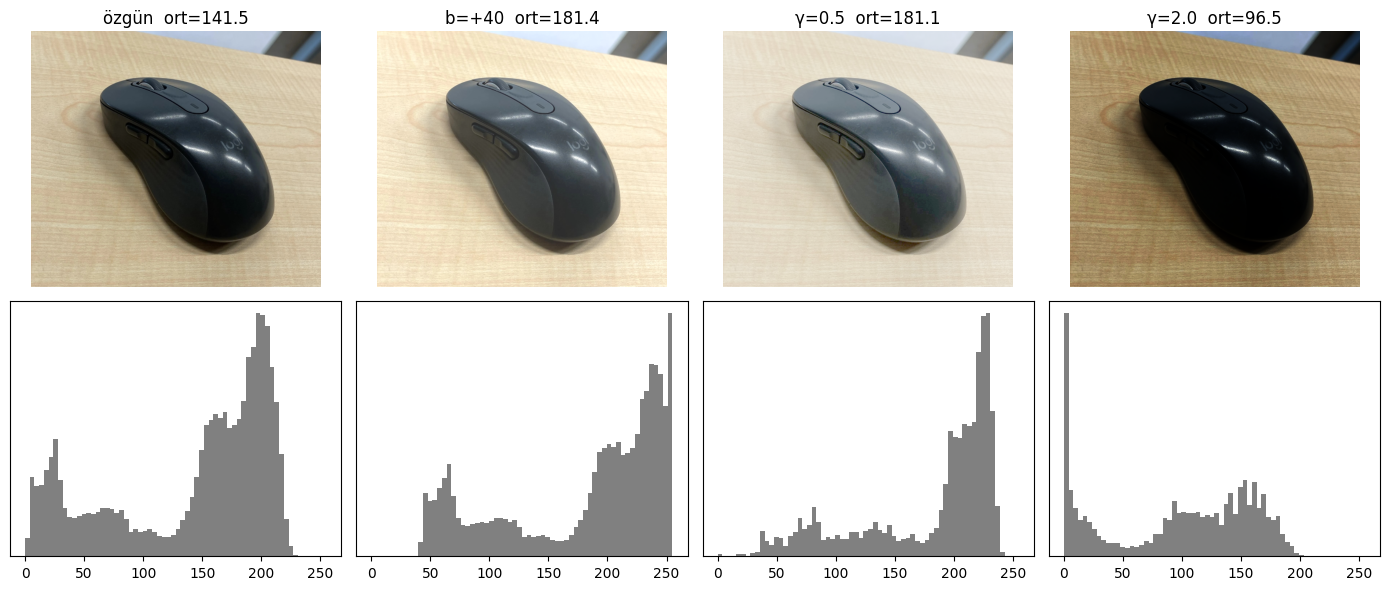

In [8]:
tahmin_kontrol("6")

def parlaklik(I, b):
    return np.clip(I.astype(np.float64) + b, 0, 255)

def gama(I, g):
    return np.clip(255.0 * (I.astype(np.float64) / 255.0) ** g, 0, 255)

def u8(J):
    return np.round(J).astype(np.uint8)

# Birim kontrol (ödevdeki örnek): 64 -> ~128 (γ=0,5), ~16 (γ=2,0)
for g in AYAR["gamalar"]:
    print(f"kontrol: 64 -> γ={g}: {gama(np.array([64]), g)[0]:.1f}")

I = rgb["normal"]
m0 = I.astype(np.float64).mean()
b = AYAR["parlaklik_b"]
donusumler = {f"b=+{b}": parlaklik(I, b)}
for g in AYAR["gamalar"]:
    donusumler[f"γ={g}"] = gama(I, g)

satirlar = [{"donusum": "özgün", "formul_tahmini_ort": round(m0, 2), "olculen_ort": round(m0, 2),
             "fark": 0.0, "255_kirpilan_%": round(100 * (I == 255).mean(), 3), "0_degerli_%": round(100 * (I == 0).mean(), 3)}]
for ad, J in donusumler.items():
    if ad.startswith("b="):
        tahmin = m0 + b
        kirp = 100 * ((I.astype(np.float64) + b) > 255).mean()
    else:
        g = float(ad.split("=")[1])
        tahmin = 255 * (m0 / 255) ** g        # "ortalamanın dönüşümü" -> Jensen nedeniyle sapar
        kirp = 100 * (J >= 255).mean()
    olc = u8(J).astype(np.float64).mean()
    satirlar.append({"donusum": ad, "formul_tahmini_ort": round(tahmin, 2), "olculen_ort": round(olc, 2),
                     "fark": round(olc - tahmin, 2), "255_kirpilan_%": round(kirp, 3),
                     "0_degerli_%": round(100 * (u8(J) == 0).mean(), 3)})
    kaydet(6, f"ortalama {ad} (formül tahmini / ölçülen)", f"{tahmin:.2f} / {olc:.2f}")
gama_df = pd.DataFrame(satirlar)
gama_df.to_csv(CIKTI / "adim6_parlaklik_gama.csv", index=False, encoding="utf-8-sig")
display(gama_df)
print("b=+40'ta ölçülen artış 40'tan küçükse kayıp, 255'te kırpılan değerlerden gelir:",
      f"beklenen kayıp = {np.mean(np.maximum(I.astype(float) + b - 255, 0)):.2f}")
print("γ satırlarındaki fark: ortalamanın gaması ≠ gamaların ortalaması (Jensen eşitsizliği); γ<1 içbükey -> ölçülen ≥ formül.")

fig, axs = plt.subplots(2, 4, figsize=(14, 6))
for j, (ad, J) in enumerate([("özgün", I.astype(float))] + list(donusumler.items())):
    axs[0, j].imshow(u8(J)); axs[0, j].set_title(f"{ad}  ort={u8(J).mean():.1f}"); axs[0, j].axis("off")
    axs[1, j].hist(u8(J).ravel(), bins=64, range=(0, 255), color="gray"); axs[1, j].set_yticks([])
plt.tight_layout(); fig.savefig(CIKTI / "adim6_donusumler.png", dpi=110); plt.show()
DONUSUMLER = donusumler

## Adım 7 — Küçültmenin etkisi (Hedef 4)
Yazılı/çizgili bölge 1/4'e `INTER_NEAREST` ve `INTER_AREA` ile küçültülür; **yalnızca göstermek için** en yakın komşuyla özgün boyuta büyütülür.

Adım 7 tahmini (çalıştırmadan önce yazılan): 'logi' harflerinin çizgileri yaklaşık 8 piksel kalınlığında, 1/4 küçültmede 2 piksele inecek. En yakın komşu bazı harf kenarlarını kopuk/basamaklı gösterecek; alan ortalaması harfleri daha gri ve bulanık ama sürekli bırakacak; büyütme kaybolan ayrıntıyı geri getirmeyecek.



,yontem,kucuk_boyut,PSNR_dB(buyutulmus vs ozgun),Laplasyen_varyansi
0,INTER_NEAREST,60x35,30.01,181.1
1,INTER_AREA,60x35,32.61,111.6
2,özgün,240x140,NaN,80.6


,baskin_periyot_ozgun_px,kontrast_std
INTER_NEAREST,12.0,120.2
INTER_AREA,12.0,30.2
özgün,3.0,120.2


Özgün kesitteki enerjinin %4.4'i 1/4 ızgaranın Nyquist sınırının üstünde -> küçültmede kalıcı olarak kaybolur ya da (en yakın komşuda) sahte düşük frekansa katlanır.


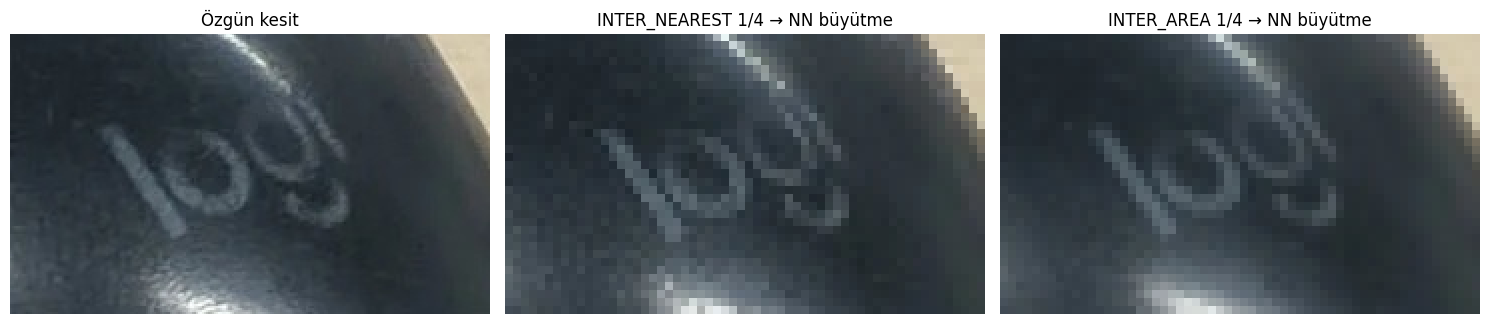

In [9]:
tahmin_kontrol("7")
k = int(AYAR["kucultme_orani"])
kesit = np.ascontiguousarray(kutu_kes(rgb["normal"], AYAR["yazi_kutu"]))
h, w = (kesit.shape[0] // k) * k, (kesit.shape[1] // k) * k     # k'nın katına kırp
kesit = np.ascontiguousarray(kesit[:h, :w])

kucuk = {"INTER_NEAREST": cv2.resize(kesit, (w // k, h // k), interpolation=cv2.INTER_NEAREST),
         "INTER_AREA":    cv2.resize(kesit, (w // k, h // k), interpolation=cv2.INTER_AREA)}
buyuk = {ad: cv2.resize(v, (w, h), interpolation=cv2.INTER_NEAREST) for ad, v in kucuk.items()}

def gri(a): return cv2.cvtColor(a, cv2.COLOR_RGB2GRAY).astype(np.float64)
def psnr(a, b_):
    mse = np.mean((gri(a) - gri(b_)) ** 2)
    return float("inf") if mse == 0 else 10 * np.log10(255 ** 2 / mse)

def nyquist_ustu_enerji(g, k):
    """Yeni ızgaranın Nyquist sınırının (1/(2k) devir/piksel) üstündeki spektral enerji payı = küçültmede KALICI kaybolan bilgi."""
    F = np.abs(np.fft.fft2(g - g.mean())) ** 2
    fy = np.abs(np.fft.fftfreq(g.shape[0]))[:, None]; fx = np.abs(np.fft.fftfreq(g.shape[1]))[None, :]
    dis = (fx > 1 / (2 * k)) | (fy > 1 / (2 * k))
    return 100 * F[dis].sum() / max(F.sum(), 1e-12)

kayip = nyquist_ustu_enerji(gri(kesit), k)
satirlar = []
for ad in kucuk:
    satirlar.append({"yontem": ad, "kucuk_boyut": f"{w // k}x{h // k}", "PSNR_dB(buyutulmus vs ozgun)": round(psnr(kesit, buyuk[ad]), 2),
                     "Laplasyen_varyansi": round(cv2.Laplacian(gri(buyuk[ad]), cv2.CV_64F).var(), 1)})
satirlar.append({"yontem": "özgün", "kucuk_boyut": f"{w}x{h}", "PSNR_dB(buyutulmus vs ozgun)": None,
                 "Laplasyen_varyansi": round(cv2.Laplacian(gri(kesit), cv2.CV_64F).var(), 1)})
kucultme_df = pd.DataFrame(satirlar)

# Kontrol deneyi: periyodu bilinen sentetik şerit (periyot 3 px < yeni Nyquist periyodu 2k px)
def baskin_periyot(sat):
    s = np.abs(np.fft.rfft(sat - sat.mean())); s[0] = 0
    f = np.fft.rfftfreq(sat.size)[np.argmax(s)]
    return float("inf") if f == 0 else 1 / f
serit = np.tile(((np.arange(240) % 3) == 0).astype(np.uint8) * 255, (60, 1))
serit_kontrol = {}
for ad, yontem in [("INTER_NEAREST", cv2.INTER_NEAREST), ("INTER_AREA", cv2.INTER_AREA)]:
    s_k = cv2.resize(serit, (240 // k, 60 // k), interpolation=yontem).astype(float)
    serit_kontrol[ad] = {"baskin_periyot_ozgun_px": round(baskin_periyot(s_k[0]) * k, 1), "kontrast_std": round(s_k.std(), 1)}
serit_kontrol["özgün"] = {"baskin_periyot_ozgun_px": round(baskin_periyot(serit[0].astype(float)), 1), "kontrast_std": round(serit.std(), 1)}
serit_df = pd.DataFrame(serit_kontrol).T

kucultme_df.to_csv(CIKTI / "adim7_kucultme.csv", index=False, encoding="utf-8-sig")
serit_df.to_csv(CIKTI / "adim7_serit_kontrol.csv", encoding="utf-8-sig")
display(kucultme_df); display(serit_df)
print(f"Özgün kesitteki enerjinin %{kayip:.1f}'i 1/{k} ızgaranın Nyquist sınırının üstünde -> küçültmede kalıcı olarak kaybolur ya da (en yakın komşuda) sahte düşük frekansa katlanır.")
kaydet(7, "Nyquist üstü enerji payı %", round(kayip, 2))
for r in satirlar[:2]:
    kaydet(7, f"PSNR dB {r['yontem']}", r["PSNR_dB(buyutulmus vs ozgun)"])
for ad, v in serit_kontrol.items():
    kaydet(7, f"şerit (periyot 3) baskın periyot / kontrast {ad}", f"{v['baskin_periyot_ozgun_px']} / {v['kontrast_std']}")

fig, axs = plt.subplots(1, 3, figsize=(15, 5 * h / w + 0.6))
for a, (ad, im) in zip(axs, [("Özgün kesit", kesit), (f"INTER_NEAREST 1/{k} → NN büyütme", buyuk["INTER_NEAREST"]),
                             (f"INTER_AREA 1/{k} → NN büyütme", buyuk["INTER_AREA"])]):
    a.imshow(im, interpolation="nearest"); a.set_title(ad); a.axis("off")
plt.tight_layout(); fig.savefig(CIKTI / "adim7_kucultme.png", dpi=130); plt.show()
KESIT, BUYUK, KAYIP = kesit, buyuk, kayip

In [10]:
# 8) Sonuç tablosu
sonuc_df = pd.DataFrame(SONUC)
sonuc_df.to_csv(CIKTI / "sonuc_tablosu.csv", index=False, encoding="utf-8-sig")
display(sonuc_df)

,adim,olcum,deger
0,4,"boyut (H,W,C)","(1411, 1600, 3)"
1,4,veri türü,uint8
2,4,değer aralığı,0-255
3,5,RGB maske alan oranı % (Normal ışık),64.172
4,5,HSV maske alan oranı % (Normal ışık),66.115
5,5,RGB maske alan oranı % (Gölge (simüle)),1.634
6,5,HSV maske alan oranı % (Gölge (simüle)),2.066
7,5,RGB maske alan oranı % (Farklı lamba (simüle)),10.315
8,5,HSV maske alan oranı % (Farklı lamba (simüle)),54.99
9,6,ortalama b=+40 (formül tahmini / ölçülen),181.50 / 181.36


## Rapor (en fazla 2 sayfa PDF)
`metin.json`'daki yorumlarınız + yukarıdaki **ölçülmüş** sayılar birleştirilir. Boş veya `TASLAK` ile başlayan alanlar kırmızı görünür — teslimden önce hepsini kendiniz doldurun.

In [11]:
plt.rcParams["font.family"] = "DejaVu Sans"
A4 = (8.27, 11.69)
FS = 6.4

def fmt_esik(e):
    return (f"R {e['rgb_alt'][0]}–{e['rgb_ust'][0]}, G {e['rgb_alt'][1]}–{e['rgb_ust'][1]}, B {e['rgb_alt'][2]}–{e['rgb_ust'][2]}; "
            f"H {e['h_alt']}–{e['h_ust']}, S ≥ {e['s_alt']}, V ≥ {e['v_alt']}")

def olcum_metni():
    o = {}
    pk = []
    for i, (px, py) in enumerate(AYAR["pikseller"]):
        d = piksel_df[piksel_df.piksel == f"P{i+1}"]
        pk.append(f"P{i+1}(x={px}, y={py}): " + ", ".join(f"{r.kosul.lower()} ({r.R}, {r.G}, {r.B})" for r in d.itertuples()))
    o["4"] = (f"img.shape = {bgr['normal'].shape}, {bgr['normal'].dtype}, {bgr['normal'].min()}–{bgr['normal'].max()}. "
              f"img[y, x, 0] OpenCV'de B kanalıdır; cv2.cvtColor(BGR2RGB) == img[..., ::-1]. " + "; ".join(pk) + ".")
    r = maske_df
    o["5"] = (f"Donmuş eşikler: {fmt_esik(ESIK)}. RGB alan oranı: " +
              ", ".join(f"{a.lower()} %{v}" for a, v in zip(r.kosul, r["RGB_alan_orani_%"])) +
              ". HSV alan oranı: " + ", ".join(f"{a.lower()} %{v}" for a, v in zip(r.kosul, r["HSV_alan_orani_%"])) +
              ". Örnek kutu içinde seçilen (RGB/HSV): " +
              ", ".join(f"{a.lower()} %{x}/%{y}" for a, x, y in zip(r.kosul, r["RGB_ornek_kutu_ici_%"], r["HSV_ornek_kutu_ici_%"])) + "." +
              (" Seçilenin nesne dışı payı (RGB/HSV): " + ", ".join(f"{a.lower()} %{x}/%{y}" for a, x, y in
               zip(r.kosul, r["RGB_secilenin_nesne_disi_%"], r["HSV_secilenin_nesne_disi_%"])) + "." if "RGB_secilenin_nesne_disi_%" in r else ""))
    g = gama_df.set_index("donusum")
    o["6"] = (f"Özgün ortalama {g.loc['özgün','olculen_ort']}. " +
              " ".join(f"{d}: formül {g.loc[d,'formul_tahmini_ort']}, ölçülen {g.loc[d,'olculen_ort']} (fark {g.loc[d,'fark']}, 255'te kırpılan %{g.loc[d,'255_kirpilan_%']})."
                       for d in g.index if d != "özgün") +
              " Kontrol: 64 → " + ", ".join(f"γ={x}: {gama(np.array([64]), x)[0]:.1f}" for x in AYAR["gamalar"]) + ".")
    kd = kucultme_df.set_index("yontem"); sd = serit_df
    o["7"] = (f"Kesit {KESIT.shape[1]}×{KESIT.shape[0]} → {KESIT.shape[1]//k}×{KESIT.shape[0]//k}. PSNR (NN-büyütülmüş vs özgün): "
              f"NEAREST {kd.loc['INTER_NEAREST','PSNR_dB(buyutulmus vs ozgun)']} dB, AREA {kd.loc['INTER_AREA','PSNR_dB(buyutulmus vs ozgun)']} dB. "
              f"Özgün enerjinin %{KAYIP:.1f}'i yeni Nyquist sınırının üstünde (kalıcı kayıp). Şerit kontrolü (gerçek periyot 3 px): "
              f"NEAREST baskın periyot {sd.loc['INTER_NEAREST','baskin_periyot_ozgun_px']} px, kontrast {sd.loc['INTER_NEAREST','kontrast_std']}; "
              f"AREA {sd.loc['INTER_AREA','baskin_periyot_ozgun_px']} px, kontrast {sd.loc['INTER_AREA','kontrast_std']} (özgün {sd.loc['özgün','kontrast_std']}).")
    return o

class Yazici:
    """Bir eksen içine sarılı metin yerleştirir; taşarsa uyarır."""
    def __init__(self, fig, rect, fs=FS):
        self.ax = fig.add_axes(rect); self.ax.axis("off")
        self.fs = fs; self.y = 1.0
        gen_in, yuk_in = rect[2] * A4[0], rect[3] * A4[1]
        self.satir = fs * 1.28 / 72 / yuk_in
        self.genislik = int(gen_in * 72 / (fs * 0.53))
        self.tasti = False
    def yaz(self, metin, kalin=False, renk="black", girinti=0):
        for parca in textwrap.wrap(str(metin), int((self.genislik - girinti) * (0.88 if kalin else 1))) or [""]:
            if self.y < self.satir:
                self.tasti = True; return
            self.ax.text(girinti / self.genislik, self.y, parca, fontsize=self.fs, va="top", ha="left",
                         weight="bold" if kalin else "normal", color=renk, transform=self.ax.transAxes)
            self.y -= self.satir
    def alan(self, etiket, metin):
        eksik = eksik_mi(metin)
        self.yaz(f"{etiket}: " + ("[DOLDURULMADI]" if not str(metin).strip() else str(metin)),
                 renk="#c00000" if eksik else "black", girinti=2)
    def bosluk(self, n=0.4): self.y -= self.satir * n

BASLIK = {"4": "Adım 4 – Sayısal yapı (H1)", "5": "Adım 5 – Sabit RGB/HSV eşikleri (H2)",
          "6": "Adım 6 – Parlaklık ve gama (H3)", "7": "Adım 7 – Küçültme (H4)"}

def deney_yaz(Y, adim, olcumler):
    d = METIN["deneyler"][adim]
    Y.yaz(BASLIK[adim], kalin=True)
    Y.alan("Tahmin (önceden)", d["tahmin"])
    Y.yaz("Ölçüm: " + olcumler[adim], girinti=2)
    Y.alan("Ne gördüm", d["ne_gordum"]); Y.alan("Neden olabilir", d["neden"]); Y.alan("Nasıl kontrol ederim", d["kontrol"])
    Y.bosluk()

def resim(fig, rect, im, baslik, cmap=None):
    ax = fig.add_axes(rect); ax.imshow(im, cmap=cmap, interpolation="nearest"); ax.axis("off")
    ax.set_title(baslik, fontsize=6.5, pad=2)

def rapor_uret(yol):
    O = olcum_metni(); tasma = []
    kucuk = lambda im: cv2.resize(im, (min(900, im.shape[1]), int(im.shape[0] * min(900, im.shape[1]) / im.shape[1])), interpolation=cv2.INTER_AREA)
    with PdfPages(yol) as pdf:
        # ---------------- Sayfa 1 ----------------
        fig = plt.figure(figsize=A4)
        fig.text(0.5, 0.982, "YZM 411 – Ödev 1: Renk, Aydınlatma ve Örnekleme", ha="center", fontsize=10.5, weight="bold")
        fig.text(0.5, 0.968, f"{METIN.get('ad_soyad') or '[Ad Soyad]'} – {AYAR['ogrenci_no']}   |   {datetime.date.today():%d.%m.%Y}",
                 ha="center", fontsize=7)
        cw, x0 = 0.31, [0.03, 0.345, 0.66]
        for j, kk in enumerate(KOSULLAR):
            resim(fig, [x0[j], 0.80, cw, 0.155], kucuk(rgb[kk]), f"{ADLAR[kk]} (özgün)")
            for i, tur in enumerate(["RGB", "HSV"]):
                resim(fig, [x0[j], 0.645 - i * 0.145, cw, 0.135], kucuk(maskeler[(kk, tur)]),
                      f"{tur} maske – {ADLAR[kk]}: alanın %{100 * (maskeler[(kk, tur)] > 0).mean():.2f}'i", cmap="gray")
        # karşılaştırma tablosu
        tax = fig.add_axes([0.03, 0.435, 0.94, 0.06]); tax.axis("off")
        kol = ["Koşul", "Örnek bölge ort. RGB", "Örnek bölge medyan HSV", "RGB alan %", "HSV alan %", "RGB kutu içi %", "HSV kutu içi %"]
        veri = [[r.kosul, str(r.ornek_bolge_ort_RGB), str(r.ornek_bolge_medyan_HSV), r["RGB_alan_orani_%"], r["HSV_alan_orani_%"],
                 r["RGB_ornek_kutu_ici_%"], r["HSV_ornek_kutu_ici_%"]] for _, r in maske_df.iterrows()]
        tb = tax.table(cellText=veri, colLabels=kol, loc="center", cellLoc="center",
                       colWidths=[0.16, 0.16, 0.18, 0.11, 0.11, 0.14, 0.14])
        tb.auto_set_font_size(False); tb.set_fontsize(6.2); tb.scale(1, 1.05)
        Y = Yazici(fig, [0.03, 0.015, 0.94, 0.41])
        if SIMULE:
            Y.yaz("SINIRLILIK: " + ", ".join(ADLAR[s] for s in SIMULE) + " görüntüleri gerçek çekim DEĞİLDİR; tek gerçek fotoğraftan "
                  "simule_et.py ile (lineer ışık uzayında kanal kazancı) üretilmiştir. Bu koşullardaki ölçümler gerçek ışığı değil modeli ölçer.",
                  kalin=True, renk="#a05000")
        Y.alan("Kamera / değişken kontrolü", METIN.get("kamera_notu", ""))
        Y.bosluk()
        deney_yaz(Y, "4", O); deney_yaz(Y, "5", O)
        Y.alan("Soru: Sarı bir arka plan neden hedef gibi seçildi?", METIN.get("soru_sari_arka_plan", ""))
        Y.yaz("Not: maske alan oranı bir doğruluk ölçütü değildir; yalnızca donmuş eşiği geçen piksellerin payıdır.", renk="#555555", girinti=2)
        if Y.tasti: tasma.append(1)
        pdf.savefig(fig); plt.close(fig)

        # ---------------- Sayfa 2 ----------------
        fig = plt.figure(figsize=A4)
        I0 = rgb["normal"]
        paneller = [("Özgün", I0)] + [(ad, u8(J)) for ad, J in DONUSUMLER.items()]
        pw = 0.94 / len(paneller)
        for j, (ad, im) in enumerate(paneller):
            resim(fig, [0.03 + j * pw, 0.85, pw - 0.01, 0.13], kucuk(im), f"{ad} – ort. {im.mean():.1f}")
        gax = fig.add_axes([0.03, 0.775, 0.94, 0.06]); gax.axis("off")
        tb = gax.table(cellText=gama_df.values.tolist(), colLabels=["Dönüşüm", "Formül tahmini ort.", "Ölçülen ort.", "Fark",
                       "255'te kırpılan %", "0 değerli %"], loc="center", cellLoc="center")
        tb.auto_set_font_size(False); tb.set_fontsize(6.2)
        ks = [("Özgün kesit", KESIT), (f"NEAREST 1/{k} → büyütme", BUYUK["INTER_NEAREST"]), (f"AREA 1/{k} → büyütme", BUYUK["INTER_AREA"])]
        for j, (ad, im) in enumerate(ks):
            resim(fig, [0.03 + j * 0.315, 0.585, 0.305, 0.17], im, ad)
        Y = Yazici(fig, [0.03, 0.015, 0.94, 0.55])
        deney_yaz(Y, "6", O); deney_yaz(Y, "7", O)
        Y.alan("Soru: Büyütme kaybolan yazıyı neden geri getirmedi?", METIN.get("soru_buyutme", ""))
        Y.alan("Tutmayan tahminim", METIN.get("tutmayan_tahmin", "")); Y.bosluk()
        Y.yaz("Yeniden çalıştırma", kalin=True)
        Y.yaz("Dosyalar: odev1.ipynb (Restart & Run All), ayarlar.json (koordinatlar, b, γ, k), metin.json, foto/*.jpg; ham sonuçlar cikti/*.csv, "
              "eşikler cikti/esikler.json. Sürümler: " + ", ".join(f"{a} {b_}" for a, b_ in SURUMLER.items() if a not in ("platform", "calistirma_zamani")) + ".", girinti=2)
        Y.bosluk()
        Y.yaz("Yapay zekâ beyanı", kalin=True); Y.alan("Beyan", METIN.get("yz_beyani", ""))
        if Y.tasti: tasma.append(2)
        pdf.savefig(fig); plt.close(fig)
    eksikler = [f"deneyler.{a}.{alan}" for a, d in METIN["deneyler"].items() for alan, v in d.items() if eksik_mi(v)]
    eksikler += [a for a in ["ad_soyad", "kamera_notu", "soru_sari_arka_plan", "soru_buyutme", "tutmayan_tahmin", "yz_beyani"] if eksik_mi(METIN.get(a, ""))]
    return tasma, eksikler

RAPOR = KOK / f"YZM411_Odev1_{AYAR['ogrenci_no']}_rapor.pdf"
tasma, eksikler = rapor_uret(RAPOR)
print("Rapor yazıldı:", RAPOR.name, "(2 sayfa)")
if tasma: print("!!! UYARI: metin şu sayfa(lar)da sığmadı, kısaltın:", tasma)
if eksikler: print("!!! Doldurulmamış / TASLAK alanlar (metin.json):", ", ".join(eksikler))

Rapor yazıldı: YZM411_Odev1_230212010_rapor.pdf (2 sayfa)
!!! Doldurulmamış / TASLAK alanlar (metin.json): ad_soyad


In [12]:
# Kaynak beyanı + teslim ZIP'i  (önce notebook'u KAYDEDİN, sonra bu hücreyi çalıştırın)
beyan = f"""# Kaynak beyanı – YZM411 Ödev 1 – {AYAR['ogrenci_no']}

## Veri
- foto/normal.jpg, foto/golge.jpg, foto/lamba.jpg: kendi çekimim, sabit kamera ve nesne konumu.
- Kamera notu: {METIN.get('kamera_notu', '')}
- EXIF özeti: cikti/exif.csv

## Kaynaklar
- YZM 411 ders notları, Hafta 1–2 (görüntünün sayısal temsili, renk uzayları, örnekleme).
- OpenCV belgeleri: cvtColor (BGR↔RGB/HSV, 8 bit HSV'de H 0–179), inRange, resize (INTER_NEAREST, INTER_AREA).

## Yapay zekâ beyanı
{METIN.get('yz_beyani', '')}

## Ortam
""" + "\n".join(f"- {a}: {b_}" for a, b_ in SURUMLER.items())
(KOK / "kaynak_beyani.md").write_text(beyan, encoding="utf-8")

ZIP = KOK / f"YZM411_Odev1_{AYAR['ogrenci_no']}.zip"
dahil = [KOK / "odev1.ipynb", RAPOR, KOK / "kaynak_beyani.md", KOK / "ayarlar.json", KOK / "metin.json", KOK / "README.md", KOK / "simule_et.py"]
dahil += sorted((KOK / "foto").glob("*")) + sorted(CIKTI.glob("*.csv")) + [CIKTI / "esikler.json"]
with zipfile.ZipFile(ZIP, "w", zipfile.ZIP_DEFLATED) as z:
    for p in dahil:
        if p.exists() and p.is_file():
            z.write(p, Path(ZIP.stem) / p.relative_to(KOK))
print("ZIP:", ZIP.name)
with zipfile.ZipFile(ZIP) as z:
    for n in z.namelist(): print("  ", n)

ZIP: YZM411_Odev1_230212010.zip
   YZM411_Odev1_230212010/odev1.ipynb
   YZM411_Odev1_230212010/YZM411_Odev1_230212010_rapor.pdf
   YZM411_Odev1_230212010/kaynak_beyani.md
   YZM411_Odev1_230212010/ayarlar.json
   YZM411_Odev1_230212010/metin.json
   YZM411_Odev1_230212010/README.md
   YZM411_Odev1_230212010/simule_et.py
   YZM411_Odev1_230212010/foto/.gitkeep
   YZM411_Odev1_230212010/foto/golge_SIMULE.jpg
   YZM411_Odev1_230212010/foto/lamba_SIMULE.jpg
   YZM411_Odev1_230212010/foto/normal.jpg
   YZM411_Odev1_230212010/cikti/adim4_pikseller.csv
   YZM411_Odev1_230212010/cikti/adim5_maskeler.csv
   YZM411_Odev1_230212010/cikti/adim6_parlaklik_gama.csv
   YZM411_Odev1_230212010/cikti/adim7_kucultme.csv
   YZM411_Odev1_230212010/cikti/adim7_serit_kontrol.csv
   YZM411_Odev1_230212010/cikti/exif.csv
   YZM411_Odev1_230212010/cikti/sonuc_tablosu.csv
   YZM411_Odev1_230212010/cikti/esikler.json
